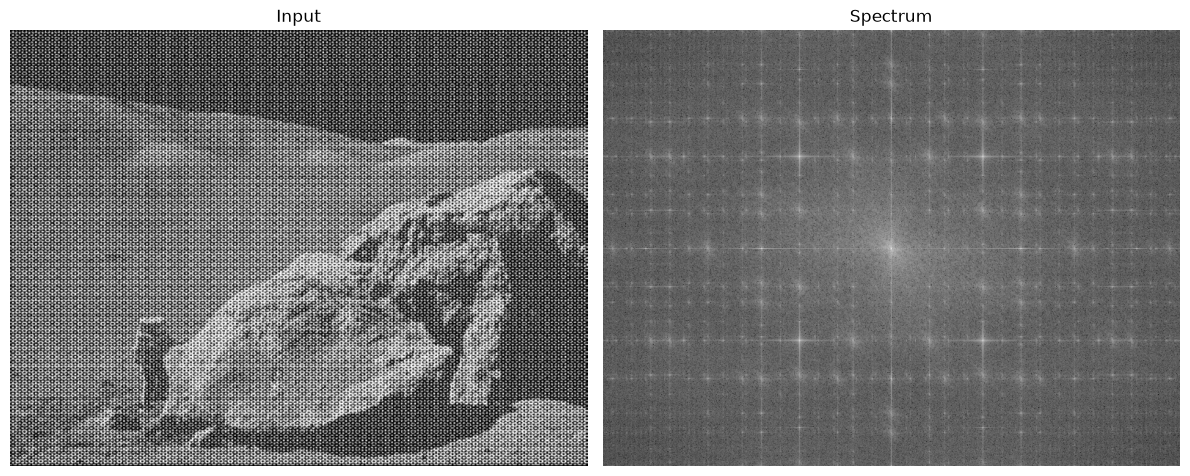

In [11]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

# прямое преобразование Фурье
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# спектр амплитуд для отображения
magnitude = 20 * np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray'); plt.title('Input'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(magnitude, cmap='gray'); plt.title('Spectrum'); plt.axis('off')
plt.tight_layout(); plt.show()

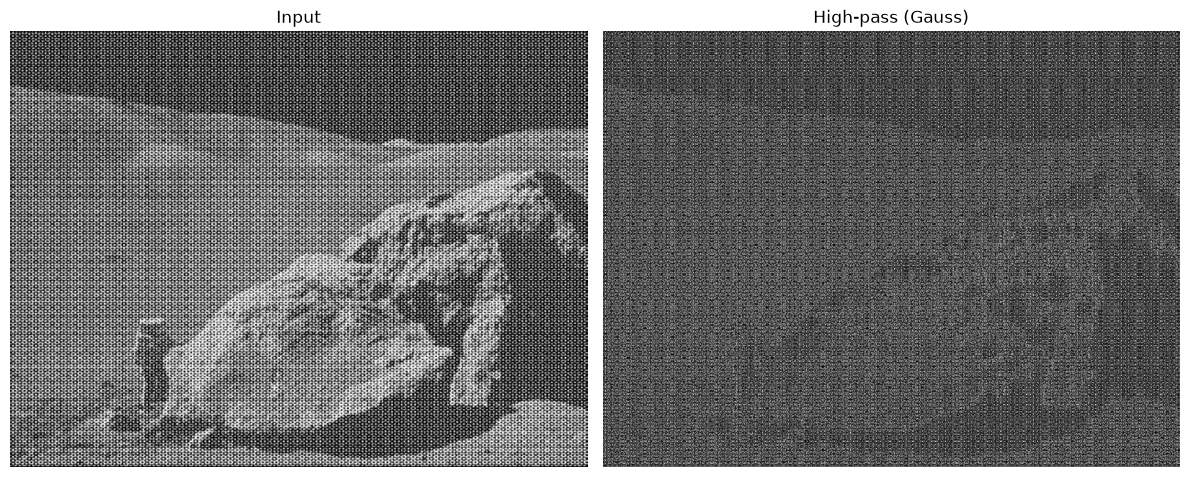

In [12]:
# 1. Высокочастотная фильтрация на основе ядра Гаусса

# ядро Гаусса в частотной области
h, w = img.shape
cx, cy = h // 2, w // 2
sigma = 30

y, x = np.ogrid[:h, :w]
gauss = 1 - np.exp(-((x - cy)**2 + (y - cx)**2) / (2 * sigma**2))

mask_hp = np.zeros((h, w, 2), np.float32)
mask_hp[:,:,0] = gauss
mask_hp[:,:,1] = gauss

# применяем фильтр
dft_hp = dft_shift * mask_hp
f_ishift = np.fft.ifftshift(dft_hp)
img_back = cv.idft(f_ishift)
img_hp = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray'); plt.title('Input'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img_hp, cmap='gray'); plt.title('High-pass (Gauss)'); plt.axis('off')
plt.tight_layout(); plt.show()

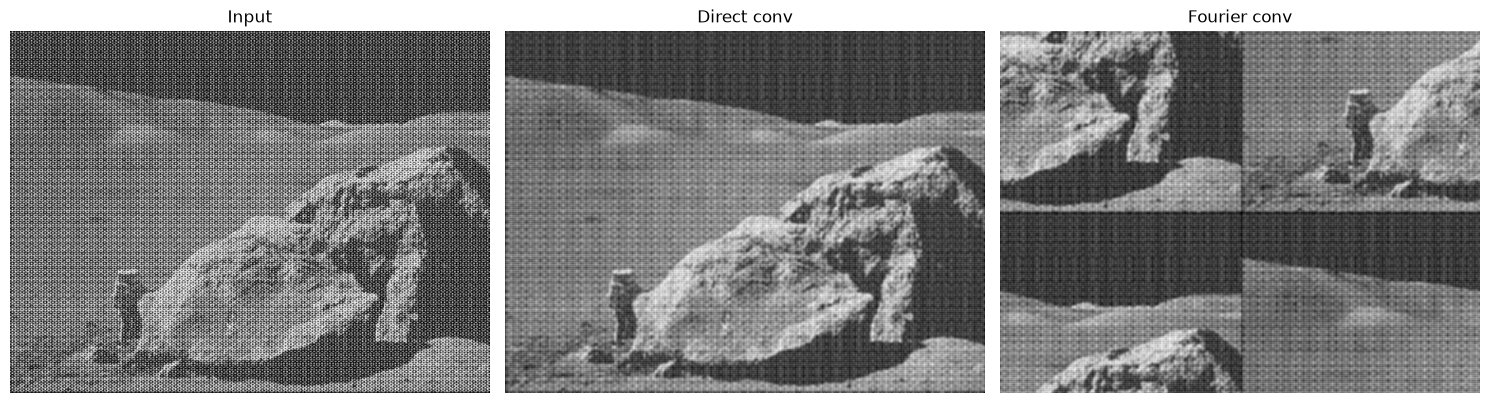

Max diff: 158.60002


In [13]:
# 2. Свёртка через преобразование Фурье

# небольшое ядро — размытие 5x5
kernel = np.ones((5, 5), np.float32) / 25

# свёртка обычная
conv_direct = cv.filter2D(img, -1, kernel)

# свёртка через Фурье
kernel_padded = np.zeros_like(img, np.float32)
kernel_padded[:5, :5] = kernel
kernel_padded = np.fft.ifftshift(kernel_padded)

dft_img = np.fft.fft2(np.float32(img))
dft_kernel = np.fft.fft2(kernel_padded)
conv_fourier = np.real(np.fft.ifft2(dft_img * dft_kernel))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(img, cmap='gray');         plt.title('Input');            plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(conv_direct, cmap='gray'); plt.title('Direct conv');      plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(conv_fourier, cmap='gray');plt.title('Fourier conv');     plt.axis('off')
plt.tight_layout(); plt.show()

print('Max diff:', np.abs(conv_direct - conv_fourier).max())

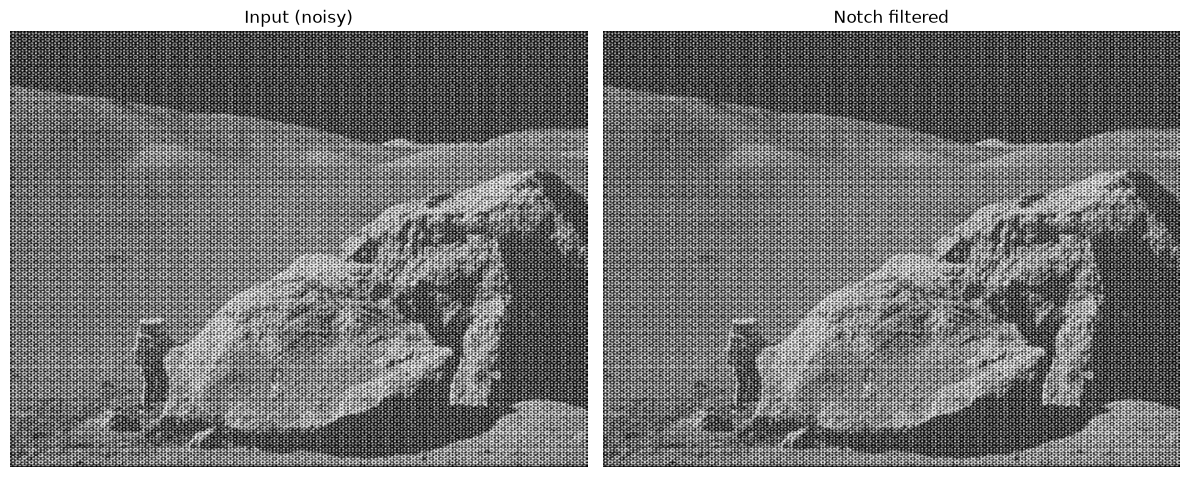

In [14]:
# 3. Удаление периодического шума через преобразование Фурье

# маска с «дырками» в местах, где сидят пики от шума
mask_notch = np.ones((img.shape[0], img.shape[1], 2), np.float32)

# центральные яркие пики от периодического шума (подбираются по спектру)
# обнуляем прямоугольные области вокруг пиков
peaks = [(10, 20), (10, 230), (230, 20), (230, 230)]  # примерные координаты
r = 8

for (py, px) in peaks:
    y0, y1 = max(py - r, 0), min(py + r, img.shape[0])
    x0, x1 = max(px - r, 0), min(px + r, img.shape[1])
    mask_notch[y0:y1, x0:x1, :] = 0

# применяем фильтр
dft_notch = dft_shift * mask_notch
f_ishift = np.fft.ifftshift(dft_notch)
img_back = cv.idft(f_ishift)
img_clean = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray');       plt.title('Input (noisy)'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img_clean, cmap='gray'); plt.title('Notch filtered'); plt.axis('off')
plt.tight_layout(); plt.show()